# Don't Get Kicked — LightGBM solution

**Task.** Predict `IsBadBuy` (is a car bought at an auction a "lemon"). Metric: ROC AUC.
This notebook reproduces the final **LightGBM** model end-to-end and writes `submission.csv` with test predictions only (no model objects are saved).

## Solution overview

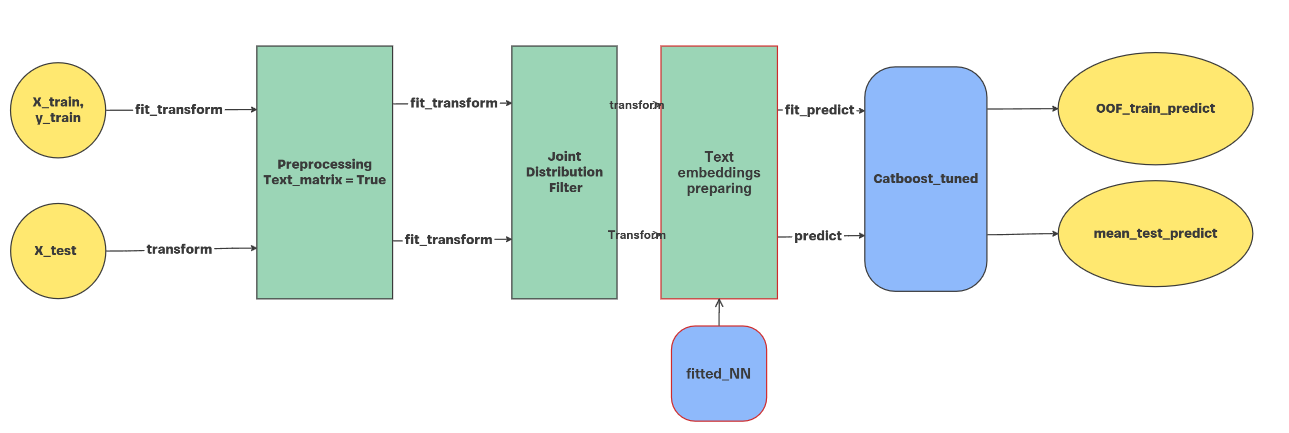

### 1. Feature engineering (`Preprocessing`)
Fitted on the training part of every fold only (no label leakage):
- **Price cleaning** – the 8 MMR price columns, `WarrantyCost` and `VehBCost` contain garbage (values < 100, NaN). Garbage is replaced by the train mean and marked with `*_is_trash` flags (flags that are highly correlated by Cramér's V are dropped).
- **Relative features** – drift between acquisition and current MMR prices, costs relative to the auction clean price, mileage per year of age.
- **Stacked factors** – small linear models turned into features: `price_factor` (polynomial logistic regression on prices), `Date_factor` (polynomial ridge on the purchase-date bucket), `text_factor` (logistic regression on Make/Model/Trim/SubModel tokens).
- Missing categories become an explicit `init_None` category.

### 2. Train/test shift control (`JointDistributionFilter`)
Values and categories that are rare in the train **or** in the test sample (share / quantile density below a threshold) are replaced by NaN, so the model never relies on values it cannot see consistently in both samples. Thresholds are tuned together with the model.

### 3. Text features from a neural network
The text columns are not given to LightGBM as a sparse matrix. The binary token matrix (`text__*`, prepared exactly as for the neural network) is passed through the **embedding layer and the first linear layer of a neural network** trained on the full train set. This yields `text_out_dim` dense features `nn_text_*` per car. **Attach the saved NN checkpoint `nn_full_model.pt` as a Kaggle dataset** and set `NN_WEIGHTS_PATH` (the pre-activation output of the linear layer is used). Two checkpoint versions are supported: the current network (`nn.Linear` over the `text__*` matrix; the columns are read from the checkpoint or rebuilt from the data) and the older one (`nn.Embedding` over token ids; the vocabulary is rebuilt from `text_min_count` in the config). The checkpoint needs `state_dict` and the network config (`model_cfg` or `config`); sizes are verified against the weights.
The network has seen the train labels, so the out-of-fold AUC printed here is optimistic; the test predictions are not affected by this.

### 4. Model
`LGBMClassifier` with native pandas categoricals; `Preprocessing` runs with default parameters and without the token matrix (`text_factor` is still produced).

### Hyper-parameter search (done offline)
Optuna on one fold tunes the JDF thresholds and the LightGBM parameters (learning rate, leaves, depth, regularisation, categorical smoothing, ...). `CFG` below is one entry of `top_params` from the resulting JSON; `N_ITER` is the number of trees at the best CV checkpoint.

### Cross-validation scheme
5 stratified folds (`random_state=42`). In every fold the whole pipeline is fitted on the training part; test predictions of the 5 fold models are averaged. Out-of-fold ROC AUC is printed as a sanity check.


In [1]:
SEED, K = 42, 5
TRAIN_PATH = "../dont_get_kicked/datasets/training.csv"
TEST_PATH = "../dont_get_kicked/datasets/test.csv"
NN_WEIGHTS_PATH = "../nn_solution/checkpoint/nn_fold0_model.pt"   # checkpoint of the neural network
OUT_PATH = "kaggle_lgbm_submission.csv"
N_ITER = 810   # number of trees (n_iter of the chosen checkpoint)

CFG = {
      "rank": 0,
      "trial": 3,
      "val_auc": 0.7958449650320131,
      "best_estimators": 747,
      "jdf": {
        "dp": 0.02760609974958405,
        "th_num_train": 0.00023233503515390126,
        "th_num_test": 0.0030586566669785274,
        "th_cat_train": 0.0011240768803005548,
        "th_cat_test": 0.02203821893928987
      },
      "lgbm": {
        "objective": "binary",
        "metric": "auc",
        "subsample_freq": 1,
        "learning_rate": 0.01814596135349025,
        "num_leaves": 308,
        "max_depth": 6,
        "min_child_samples": 57,
        "subsample": 0.7733551396716398,
        "colsample_bytree": 0.42939811886786894,
        "reg_alpha": 5.324289357128436,
        "reg_lambda": 0.09466630153726856
      }
    }

## Code: preprocessing classes (copied from the project)

In [2]:
import re
from collections import Counter
from typing import Optional

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import lightgbm as lgb

MMR_COLS = ['MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice']
NUMER_COLS = MMR_COLS + ['WarrantyCost', 'VehBCost']
CAT_COLS = ['Auction', 'BYRNO', 'VNZIP1', 'VNST', 'VehYear', 'Make', 'Model', 'Trim', 'SubModel', 'WheelType', 'Size', 'Color', 'PRIMEUNIT']
TEXT_COLS = ['Make', 'Model', 'Trim', 'SubModel']
DEFAULT_JDF_NUM_COLS = ['WarrantyCost', 'VehBCost', 'REL_DRIFT_RET_CLEAN', 'REL_DRIFT_RET_AVG', 'REL_DRIFT_AUC_AVG', 'REL_WarrantyCost', 'REL_VehBCost', 'VehOdo', 'VEHODO/VEHICLEAGE']
DEFAULT_JDF_CAT_COLS = list(CAT_COLS) + ['date_days_count']
TOKEN_RE = re.compile('[a-z0-9]+')
PURCH_DATE_ORIGIN = pd.Timestamp('2009-01-05')

class Preprocessing(BaseEstimator, TransformerMixin):

    def __init__(self, mmr_cols: Optional[list]=None, numer_cols: Optional[list]=None, cat_cols: Optional[list]=None, text_cols: Optional[list]=None, price_trash_threshold: float=100.0, cramer_v_min: float=0.5, price_pipeline_degree: int=3, price_pipeline_alpha: float=0.007, text_min_count_train: int=100, text_logreg_C: float=65.0, add_text_binary_matrix: bool=False, date_pipeline_degree: int=13, date_pipeline_alpha: float=0.007, date_days: int=14, min_flag_count: int=500, weekday_type: Optional[str]=None):
        self.mmr_cols = list(mmr_cols) if mmr_cols is not None else list(MMR_COLS)
        self.numer_cols = list(numer_cols) if numer_cols is not None else list(NUMER_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(CAT_COLS)
        self.text_cols = list(text_cols) if text_cols is not None else list(TEXT_COLS)
        self.price_trash_threshold = price_trash_threshold
        self.cramer_v_min = cramer_v_min
        self.price_pipeline_degree = price_pipeline_degree
        self.price_pipeline_alpha = price_pipeline_alpha
        self.text_min_count_train = text_min_count_train
        self.text_logreg_C = text_logreg_C
        self.add_text_binary_matrix = add_text_binary_matrix
        self.date_pipeline_degree = date_pipeline_degree
        self.date_pipeline_alpha = date_pipeline_alpha
        self.date_days = date_days
        self.min_flag_count = min_flag_count
        self.weekday_type = weekday_type
        self.numer_cols_means = {}
        self.text_vocab = set()
        self.text_model = None
        self.text_vector_names = []
        self.price_pipeline = None
        self.date_ppl = None
        self.trash_flag_cols = []

    @staticmethod
    def _cramers_v(x, y):
        x = np.asarray(x)
        y = np.asarray(y)
        confusion = pd.crosstab(x, y)
        try:
            from scipy.stats import chi2_contingency
            chi2, _, _, _ = chi2_contingency(confusion.values)
        except Exception:
            chi2 = 0.0
        n = confusion.values.sum()
        phi2 = chi2 / n
        r, k = confusion.shape
        phi2corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
        rcorr = r - (r - 1) ** 2 / (n - 1)
        kcorr = k - (k - 1) ** 2 / (n - 1)
        denom = min(kcorr - 1, rcorr - 1)
        if denom <= 0:
            return 0.0
        return np.sqrt(phi2corr / denom)

    @staticmethod
    def _build_text(X):
        return (X['Make'].fillna('').astype(str) + ' ' + X['Model'].fillna('').astype(str) + ' ' + X['Trim'].fillna('').astype(str) + ' ' + X['SubModel'].fillna('').astype(str)).str.lower()

    @classmethod
    def _token_lists(cls, X):
        text = cls._build_text(X)
        return text.map(lambda s: list(dict.fromkeys(TOKEN_RE.findall(s)))).tolist()

    def _token_matrix(self, token_lists):
        index = {t: j for j, t in enumerate(self.text_vector_names)}
        matrix = np.zeros((len(token_lists), len(index)), dtype=np.uint8)
        for i, toks in enumerate(token_lists):
            for t in toks:
                j = index.get(t)
                if j is not None:
                    matrix[i, j] = 1
        return matrix

    def _trash_mask(self, s):
        return (s < self.price_trash_threshold) | s.isna()

    def _clean_numeric(self, X):
        X_num = X[self.numer_cols].copy().astype(float)
        for col in self.numer_cols:
            X_num.loc[self._trash_mask(X_num[col]), col] = self.numer_cols_means[col]
        return X_num

    def _date_frame(self, X):
        return pd.DataFrame({'PurchDate': (X['PurchDate'] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)})

    def _fill_cat_none(self, X):
        for col in self.cat_cols:
            if col in X.columns:
                X[col] = X[col].fillna('init_None').astype(str)
        return X

    def fit(self, X, y):
        X = X.copy()
        X['PurchDate'] = pd.to_datetime(X['PurchDate'])
        y_arr = y.values.astype(float) if hasattr(y, 'values') else np.asarray(y, dtype=float)
        self.numer_cols_means = {}
        for col in self.numer_cols:
            self.numer_cols_means[col] = X.loc[~self._trash_mask(X[col]), col].mean()
        trash_flags = {f'{col}_is_trash': self._trash_mask(X[col]).astype(int) for col in self.numer_cols}
        flag_cols = list(trash_flags.keys())
        keep_flags = list(flag_cols)
        for i, c1 in enumerate(flag_cols):
            for c2 in flag_cols[i + 1:]:
                v = self._cramers_v(trash_flags[c1], trash_flags[c2])
                if v > self.cramer_v_min:
                    if trash_flags[c1].mean() < trash_flags[c2].mean():
                        if c1 in keep_flags:
                            keep_flags.remove(c1)
                    elif c2 in keep_flags:
                        keep_flags.remove(c2)
        for c in list(keep_flags):
            if trash_flags[c].sum() < self.min_flag_count:
                keep_flags.remove(c)
        self.trash_flag_cols = keep_flags
        X_num = self._clean_numeric(X)
        self.price_pipeline = Pipeline([('SS1', StandardScaler()), ('PT', PolynomialFeatures(self.price_pipeline_degree, include_bias=False)), ('SS2', StandardScaler()), ('LR', LogisticRegression(C=100, max_iter=10000))]).fit(X_num, y_arr)
        self.date_ppl = Pipeline([('ss1', StandardScaler()), ('pt', PolynomialFeatures(degree=self.date_pipeline_degree, include_bias=False)), ('ss2', StandardScaler()), ('lr', Ridge(alpha=self.date_pipeline_alpha))]).fit(self._date_frame(X), y_arr)
        Xp = self._fill_cat_none(X.copy())
        token_lists = self._token_lists(Xp)
        token_counts = Counter((t for toks in token_lists for t in toks))
        thr = self.text_min_count_train
        if isinstance(thr, float):
            thr = thr * len(Xp)
        self.text_vocab = {t for t, c in token_counts.items() if c >= thr}
        self.text_vector_names = sorted(self.text_vocab)
        if self.text_vector_names:
            token_matrix = self._token_matrix(token_lists)
            self.text_model = LogisticRegression(C=self.text_logreg_C, max_iter=5000)
            self.text_model.fit(token_matrix, y_arr)
        else:
            self.text_model = None
        return self

    def transform(self, X):
        X = X.copy()
        X['PurchDate'] = pd.to_datetime(X['PurchDate'])
        X = self._fill_cat_none(X)
        X_trans = self._clean_numeric(X)
        divisor = X_trans['MMRAcquisitionAuctionCleanPrice'].copy()
        X_trans['price_factor'] = self.price_pipeline.predict_proba(X_trans[self.numer_cols])[:, 1]
        for col in self.cat_cols:
            if col in X.columns:
                X_trans[col] = X[col]
        for col_base in self.numer_cols:
            flag_name = f'{col_base}_is_trash'
            if flag_name in self.trash_flag_cols:
                X_trans[flag_name] = self._trash_mask(X[col_base]).astype(int)
        token_matrix = None
        if self.text_vector_names:
            token_matrix = self._token_matrix(self._token_lists(X))
        if self.add_text_binary_matrix and token_matrix is not None:
            ohe_df = pd.DataFrame(token_matrix, columns=[f'text__{t}' for t in self.text_vector_names], index=X.index)
            X_trans = pd.concat([X_trans, ohe_df], axis=1)
        X_trans['REL_DRIFT_RET_CLEAN'] = (X_trans['MMRCurrentRetailCleanPrice'] - X_trans['MMRAcquisitonRetailCleanPrice']) / X_trans['MMRAcquisitonRetailCleanPrice']
        X_trans['REL_DRIFT_RET_AVG'] = (X_trans['MMRCurrentRetailAveragePrice'] - X_trans['MMRAcquisitionRetailAveragePrice']) / X_trans['MMRAcquisitionRetailAveragePrice']
        X_trans['REL_DRIFT_AUC_AVG'] = (X_trans['MMRCurrentAuctionAveragePrice'] - X_trans['MMRAcquisitionAuctionAveragePrice']) / X_trans['MMRAcquisitionAuctionAveragePrice']
        X_trans.drop(columns=self.numer_cols[:len(MMR_COLS)], inplace=True, errors='ignore')
        rel_cols = ['WarrantyCost', 'VehBCost']
        X_trans[['REL_' + col for col in rel_cols]] = X_trans[rel_cols].values / divisor.values.reshape(-1, 1)
        X_trans[['VehOdo', 'VehicleAge']] = X[['VehOdo', 'VehicleAge']]
        X_trans['VEHODO/VEHICLEAGE'] = X['VehOdo'] / (X['VehicleAge'] + 1)
        if self.text_model is not None and token_matrix is not None:
            X_trans['text_factor'] = self.text_model.predict_proba(token_matrix)[:, 1]
        X_trans['Date_factor'] = self.date_ppl.predict(self._date_frame(X))
        X_trans['date_days_count'] = ((X['PurchDate'] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)).astype('category')
        if self.weekday_type is not None:
            wd = X['PurchDate'].dt.weekday
            X_trans['weekday'] = wd.astype('category') if self.weekday_type == 'category' else wd.astype(float)
        for col in self.cat_cols:
            if col in X_trans.columns:
                X_trans[col] = X_trans[col].astype('category')
        return X_trans

    def fit_transform(self, X, y=None, **fit_params):
        self.fit(X, y)
        return self.transform(X)

class JointDistributionFilter(TransformerMixin):

    def __init__(self, X_train, X_test=None, num_cols=None, cat_cols=None, dp: float=0.02, th_num_train: float=0.001, th_num_test: float=0.001, th_cat_train: float=0.005, th_cat_test: float=0.005, min_dx_frac: float=0.001, bin_prefix: str='text__', verbose: bool=False):
        self.dp = dp
        self.th_num_train = th_num_train
        self.th_num_test = th_num_test
        self.th_cat_train = th_cat_train
        self.th_cat_test = th_cat_test
        self.min_dx_frac = min_dx_frac
        self.bin_prefix = bin_prefix
        self.verbose = verbose
        self.num_cols = list(num_cols) if num_cols is not None else list(DEFAULT_JDF_NUM_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(DEFAULT_JDF_CAT_COLS)
        self.train_profiles = {}
        self.test_profiles = {}
        self.bin_train_freq = {}
        self.bin_test_freq = {}
        self.bin_cols_to_drop_ = []
        self._build_profiles(X_train, is_test=False)
        if X_test is not None:
            self._build_profiles(X_test, is_test=True)
        self._build_bin_freqs(X_train, X_test)

    def _num_profile(self, s):
        x = pd.to_numeric(s, errors='coerce').dropna()
        n = len(x)
        if n == 0:
            return None
        shares = x.value_counts(normalize=True)
        heavy = shares[shares >= self.dp]
        heavy_shares = heavy.to_dict()
        rest = x[~x.isin(heavy.index)].values
        profile = {'heavy': heavy_shares, 'cx': None, 'log_cy': None}
        if len(rest) < 2:
            return profile
        rng = rest.max() - rest.min()
        if rng <= 0:
            return profile
        n_bins = int(round(1 / self.dp))
        edges = np.quantile(rest, np.linspace(0, 1, n_bins + 1))
        dx = np.maximum(np.diff(edges), self.min_dx_frac * rng)
        dens = 1.0 / n_bins / dx * rng
        centers = (edges[:-1] + edges[1:]) / 2.0
        cx = np.concatenate([[edges[0]], centers, [edges[-1]]])
        cy = np.concatenate([[dens[0]], dens, [dens[-1]]])
        profile['cx'], profile['log_cy'] = (cx, np.log(cy))
        return profile

    def _build_profiles(self, df, is_test: bool=False):
        profiles = {}
        for col in self.num_cols:
            if col in df.columns:
                p = self._num_profile(df[col])
                if p is not None:
                    profiles[col] = p
        for col in self.cat_cols:
            if col in df.columns:
                profiles[col] = df[col].value_counts(normalize=True).to_dict()
        if is_test:
            self.test_profiles = profiles
        else:
            self.train_profiles = profiles

    def _build_bin_freqs(self, X_train, X_test=None):
        bin_cols = [c for c in X_train.columns if str(c).startswith(self.bin_prefix)]
        self.bin_train_freq = {c: float(pd.to_numeric(X_train[c], errors='coerce').fillna(0).mean()) for c in bin_cols}
        self.bin_test_freq = {}
        if X_test is not None:
            self.bin_test_freq = {c: float(pd.to_numeric(X_test[c], errors='coerce').fillna(0).mean()) for c in bin_cols if c in X_test.columns}
        drop = []
        for c in bin_cols:
            if self.bin_train_freq[c] < self.th_cat_train:
                drop.append(c)
            elif X_test is not None and self.bin_test_freq.get(c, 0.0) < self.th_cat_test:
                drop.append(c)
        self.bin_cols_to_drop_ = drop
        if self.verbose:
            print(f'binary {self.bin_prefix}* columns: dropping {len(drop)} of {len(bin_cols)}')

    @staticmethod
    def _num_pass_mask(x, profile, th_num, th_heavy):
        if profile['cx'] is None:
            mask = np.zeros(len(x), dtype=bool)
        else:
            log_d = np.interp(x, profile['cx'], profile['log_cy'], left=-np.inf, right=-np.inf)
            mask = np.exp(log_d) >= th_num
        if profile['heavy']:
            share = pd.Series(x).map(profile['heavy']).values
            is_heavy = ~np.isnan(share)
            mask = np.where(is_heavy, np.nan_to_num(share) >= th_heavy, mask)
        return mask

    @staticmethod
    def _cat_share(values, profile):
        s = pd.Series(np.asarray(values, dtype=object))
        return s.map(profile).astype(float).fillna(0.0).values

    def _surviving_categories(self, col):
        cats = []
        test_profile = self.test_profiles.get(col)
        for k, share in self.train_profiles[col].items():
            if share < self.th_cat_train or share <= 0:
                continue
            if test_profile is not None and test_profile.get(k, 0.0) < self.th_cat_test:
                continue
            cats.append(k)
        return cats

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in self.num_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            x = pd.to_numeric(X_out[col], errors='coerce').astype(float).values
            final = self._num_pass_mask(x, self.train_profiles[col], self.th_num_train, self.th_cat_train)
            if col in self.test_profiles:
                final &= self._num_pass_mask(x, self.test_profiles[col], self.th_num_test, self.th_cat_test)
            was_nan = np.isnan(x)
            out = x.copy()
            out[~final] = np.nan
            X_out[col] = out
            if self.verbose:
                print(f'{col}: masked {(~final & ~was_nan).mean():.2%} of values')
        for col in self.cat_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            vals = X_out[col].values
            final = self._cat_share(vals, self.train_profiles[col]) >= self.th_cat_train
            if col in self.test_profiles:
                final &= self._cat_share(vals, self.test_profiles[col]) >= self.th_cat_test
            cats = self._surviving_categories(col)
            X_out[col] = pd.Series(np.asarray(X_out[col].values, dtype=object), index=X_out.index).where(final).astype(pd.CategoricalDtype(categories=cats))
            if self.verbose:
                print(f'{col}: masked {(~final).mean():.2%} of values')
        drop_cols = [c for c in self.bin_cols_to_drop_ if c in X_out.columns]
        if drop_cols:
            X_out = X_out.drop(columns=drop_cols)
        return X_out

## Data

In [3]:
train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)
train["PurchDate"], test["PurchDate"] = pd.to_datetime(train["PurchDate"]), pd.to_datetime(test["PurchDate"])
y = train["IsBadBuy"]
X, X_test, ref_id = train.drop(columns=["IsBadBuy", "RefId"]), test.drop(columns=["RefId"]), test["RefId"]
folds = list(StratifiedKFold(K, shuffle=True, random_state=SEED).split(X, y))
print(X.shape, X_test.shape, "positive rate:", round(y.mean(), 4))

(72983, 32) (48707, 32) positive rate: 0.123


## Text features: token matrix -> NN embedding layer -> first linear layer

In [4]:
import torch

ckpt = torch.load(NN_WEIGHTS_PATH, map_location="cpu")
sd, cfg = ckpt["state_dict"], ckpt.get("model_cfg") or ckpt.get("config")      # key names differ between checkpoint versions
spec = ckpt["spec"] if isinstance(ckpt.get("spec"), dict) else {}
E, W_out, b_out = (sd[k].float().numpy() for k in ("text_emb.weight", "text_out.0.weight", "text_out.0.bias"))
emb_dim, normalize = W_out.shape[1], bool(cfg["normalize_text"])          # embedding size = input size of the first linear layer
print("text_emb.weight:", E.shape, "| embedding size:", emb_dim, "| checkpoint keys:", list(ckpt), "| spec keys:", list(spec))

# the embedding block is either nn.Linear(n_tokens, emb_dim)  -> weight (emb_dim, n_tokens)
# or (older network) nn.Embedding(vocab, emb_dim)             -> weight (vocab, emb_dim), row 0 is padding
is_embedding = E.shape[1] == emb_dim and E.shape[0] != emb_dim
E = E[1:] if is_embedding else E.T          # -> (n_tokens, emb_dim)
n_tokens = E.shape[0]

def nn_text(M, index):                      # multi-hot token matrix -> embedding layer -> first linear layer
    e = M @ E
    if normalize:
        e = e / np.clip(M.sum(1, keepdims=True), 1, None)
    return pd.DataFrame(e @ W_out.T + b_out, columns=[f"nn_text_{i}" for i in range(W_out.shape[0])], index=index)

if is_embedding:
    # older network: vocabulary = tokens of "Make Model Trim SubModel" seen >= text_min_count times, plus "none"
    tokenize = lambda d: ((d["Make"].fillna("") + " " + d["Model"].fillna("") + " " + d["Trim"].fillna("") + " " + d["SubModel"].fillna(""))
                          .str.lower().map(lambda s: list(dict.fromkeys(re.findall(r"[a-z0-9]+", s)))))
    rows_all = tokenize(X)
    def make_vocab(rows):
        cnt = Counter(t for r in rows for t in r)
        return sorted({t for t, c in cnt.items() if c >= int(cfg["text_min_count"])} | {"none"})
    # the vocabulary was fitted either on the whole train set or on the training part of fold 0
    vocab = next((v for v in (make_vocab(rows_all), make_vocab(rows_all.iloc[folds[0][0]])) if len(v) == n_tokens), None)
    assert vocab is not None, f"cannot rebuild the {n_tokens}-token vocabulary (text_min_count={cfg.get('text_min_count')})"
    index = {t: i for i, t in enumerate(vocab)}
    def text_matrix(d):
        M = np.zeros((len(d), n_tokens), np.float32)
        for i, row in enumerate(tokenize(d)):
            for t in row:
                if t in index:
                    M[i, index[t]] = 1
        M[M.sum(1) == 0, index["none"]] = 1                 # empty text -> the "none" token, as in the network
        return M
    text_train, text_test = nn_text(text_matrix(X), X.index), nn_text(text_matrix(X_test), X_test.index)
    print("vocabulary rebuilt from the data:", n_tokens, "tokens")
else:
    # current network: columns text__* of Preprocessing(add_text_binary_matrix=True) + default JDF
    tp = Preprocessing(add_text_binary_matrix=True).fit(X, y)
    Xp, Xtp = tp.transform(X), tp.transform(X_test)
    tj = JointDistributionFilter(Xp, Xtp)
    Xf, Xtf = tj.transform(Xp), tj.transform(Xtp)
    tokens = ckpt.get("tokens")
    if tokens is None:
        tokens = next((spec[k] for k in ("tokens", "text_tokens", "text_cols", "text_names") if k in spec), None)
    if tokens is not None:
        cols = [t if str(t).startswith("text__") else "text__" + str(t) for t in tokens]
    else:
        cols = [c for c in Xf.columns if str(c).startswith("text__")]
    assert len(cols) == n_tokens, (f"the network has {n_tokens} text inputs but {len(cols)} text__ columns were found: "
                                   "Preprocessing / JDF parameters differ from those used to train the network")
    print("text columns:", n_tokens, "| taken from", "the checkpoint" if tokens is not None else "the data")
    text_train = nn_text(Xf[cols].to_numpy(np.float32), Xf.index)
    text_test = nn_text(Xtf[cols].to_numpy(np.float32), Xtf.index)
print("nn_text features:", text_train.shape[1])

text_emb.weight: (303, 128) | embedding size: 128 | checkpoint keys: ['state_dict', 'config', 'spec'] | spec keys: ['vocab_size', 'embed_cards', 'ohe_dim', 'cont_dim', 'embed_cols']
vocabulary rebuilt from the data: 302 tokens
nn_text features: 8


## Training: 5 folds, pipeline fitted inside every fold, averaged test predictions

In [5]:
def drop_empty_cats(*frames):
    """Drop categorical columns left without any category after the JDF (all values became NaN)."""
    empty = [c for c in frames[0] if isinstance(frames[0][c].dtype, pd.CategoricalDtype) and len(frames[0][c].cat.categories) == 0]
    return [f.drop(columns=empty) for f in frames]

def with_text(frame, text):
    out = pd.concat([frame, text.loc[frame.index]], axis=1)
    out.columns = [re.sub(r"[^0-9a-zA-Z_]+", "_", str(c)) for c in out.columns]   # LightGBM dislikes special characters
    return out

oof, test_pred = np.zeros(len(X)), np.zeros(len(X_test))
for k, (tr, va) in enumerate(folds):
    prep = Preprocessing().fit(X.iloc[tr], y.iloc[tr])
    Xtr, Xva, Xte = (prep.transform(d) for d in (X.iloc[tr], X.iloc[va], X_test))
    jdf = JointDistributionFilter(Xtr, Xte, **CFG["jdf"])
    Xtr, Xva, Xte = drop_empty_cats(*(jdf.transform(d) for d in (Xtr, Xva, Xte)))
    Xtr, Xva, Xte = with_text(Xtr, text_train), with_text(Xva, text_train), with_text(Xte, text_test)
    model = lgb.LGBMClassifier(n_estimators=N_ITER, random_state=SEED, verbose=-1, **CFG["lgbm"]).fit(Xtr, y.iloc[tr])
    oof[va] = model.predict_proba(Xva)[:, 1]
    test_pred += model.predict_proba(Xte)[:, 1] / K
    print(f"fold {k}: features={Xtr.shape[1]}, val AUC={roc_auc_score(y.iloc[va], oof[va]):.5f}")

fold 0: features=36, val AUC=0.79185
fold 1: features=36, val AUC=0.78867
fold 2: features=36, val AUC=0.80171
fold 3: features=36, val AUC=0.79596
fold 4: features=36, val AUC=0.78965


## Submission

In [6]:
print("OOF ROC AUC:", round(roc_auc_score(y, oof), 5))
pd.DataFrame({"RefId": ref_id, "IsBadBuy": test_pred}).to_csv(OUT_PATH, index=False)
print("saved", OUT_PATH)

OOF ROC AUC: 0.79347
saved kaggle_lgbm_submission.csv


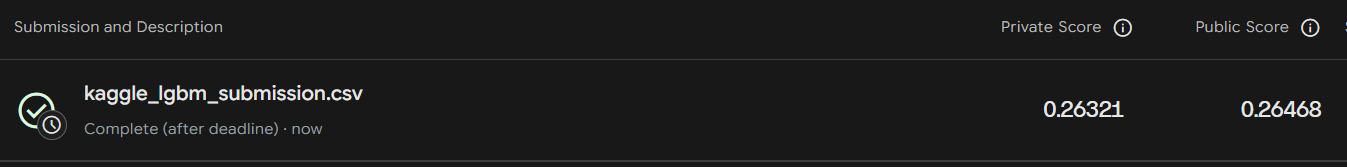